# Bradley CAT 2 work



## Source and task



In [10]:
# The supplied source is mdb-1815 GTFS snapshot.
# The historical stop-matching task is
# The queries are team-authored test inputs, not real rider aliases.

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Load and inspect
Loading and inspection code. Preserved IDs as text.


In [11]:
#Version 3
# import pandas as pd
# stops = pd.read_csv("/content/drive/MyDrive/gtfs/stops.txt", dtype=str, keep_default_na=False)
# trips = pd.read_csv("/content/drive/MyDrive/gtfs/trips.txt", dtype=str, keep_default_na=False)
# stop_times = pd.read_csv("/content/drive/MyDrive/gtfs/stop_times.txt", dtype=str, keep_default_na=False)
# for df in (stops, trips, stop_times):
#     print(df.shape); display(df.head()); print(df.dtypes)
# print("blank stop_name:", (stops["stop_name"].str.strip() == "").sum())
# print("duplicate stop_id in stops:", stops["stop_id"].duplicated().sum())
# print("direction values:", trips["direction_id"].unique())
# print("route 50205012511 trips:", (trips["route_id"] == "50205012511").sum())


(4284, 6)


,stop_id,stop_name,stop_lat,stop_lon,location_type,parent_station
0,0001RLW,Railways,-1.290884,36.828242,0,
1,0002KOJ,Koja,-1.28123,36.822596,1,
2,0003NGR,Ngara,-1.274395,36.823806,1,
3,0004ODN,Odeon,-1.282769,36.825032,1,
4,0005AMB,Kencom/Ambassadeur,-1.285963,36.826048,1,


stop_id           object
stop_name         object
stop_lat          object
stop_lon          object
location_type     object
parent_station    object
dtype: object
(272, 6)


,route_id,service_id,trip_id,trip_headsign,direction_id,shape_id
0,10000107D11,DAILY,1107D110,Ruaka,0,1107D110
1,10000107D11,DAILY,1107D111,Ruiru,1,1107D111
2,10000114011,DAILY,10114110,Ngara,0,10114110
3,10000114011,DAILY,10114111,Limuru,1,10114111
4,10000116011,DAILY,10116110,Koja,0,10116110


route_id         object
service_id       object
trip_id          object
trip_headsign    object
direction_id     object
shape_id         object
dtype: object
(7533, 5)


,trip_id,arrival_time,departure_time,stop_id,stop_sequence
0,10106110,6:00:00,6:00:20,0110BAA,1
1,10106110,6:00:34,6:00:54,0110BNI,2
2,10106110,6:01:10,6:01:30,0110UMK,3
3,10106110,6:01:49,6:02:09,0110AEA,4
4,10106110,6:02:45,6:03:05,0100MOM,5


trip_id           object
arrival_time      object
departure_time    object
stop_id           object
stop_sequence     object
dtype: object
blank stop_name: 0
duplicate stop_id in stops: 0
direction values: ['0' '1']
route 50205012511 trips: 2


In [4]:
#Version 4
import os, re, sys, random, shutil, zipfile, unicodedata
import pandas as pd

BASE = '/content/drive/MyDrive/gtfs' # this folder holds stops.txt, trips.txt, stop_times.txt

SETUP = f'{BASE}/setup' # setup handoff files
REVIEWED = f'{BASE}/reviewed' # reviewed-data handoff files
ROUTE_ID = '50205012511' # route short name 125
os.makedirs(SETUP, exist_ok=True)
os.makedirs(REVIEWED, exist_ok=True)
print(sys.version)
print('pandas', pd.__version__)
print(os.listdir(BASE))


3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
pandas 2.2.3
['feed_info.txt', 'routes.txt', 'stop_times.txt', 'stops.txt', 'trips.txt', 'queries_bradley_v1.csv', 'queries_kate_v1.csv', 'setup', 'reviewed', 'Bradley_Setup_v1.zip']


In [5]:
def load(name):
  return pd.read_csv(f'{BASE}/{name}.txt', dtype=str,
keep_default_na=False)
stops, trips, stop_times = load('stops'), load('trips'), load('stop_times')
for name, df in [('stops', stops), ('trips', trips), ('stop_times',
stop_times)]:
  print(f'\n{name}: {df.shape}')
display(df.head(3))
print('blank stop_name:', (stops['stop_name'].str.strip() == '').sum())
print('duplicate stop_id in stops:', stops['stop_id'].duplicated().sum())
print('direction values:', trips['direction_id'].unique())
print('trips on route 125:', (trips['route_id'] == ROUTE_ID).sum())


stops: (4284, 6)

trips: (272, 6)

stop_times: (7533, 5)


,trip_id,arrival_time,departure_time,stop_id,stop_sequence
0,10106110,6:00:00,6:00:20,0110BAA,1
1,10106110,6:00:34,6:00:54,0110BNI,2
2,10106110,6:01:10,6:01:30,0110UMK,3


blank stop_name: 0
duplicate stop_id in stops: 0
direction values: ['0' '1']
trips on route 125: 2


## Catalogue and selected groups



In [2]:
#Version 0
# first normalization and filtering
# import unicodedata, re
# def normalize(s):
#     s = unicodedata.normalize("NFKC", s).lower().strip()
#     return re.sub(r"\s+", " ", s)

In [6]:
#Version 1
def normalize(s):
  s = unicodedata.normalize('NFKC', s).lower().strip()
  return re.sub(r'\s+', ' ', s)
route_trips = trips.loc[trips['route_id'] == ROUTE_ID, ['trip_id',
'route_id', 'direction_id']]
assert len(route_trips) > 0
memberships = (stop_times[['trip_id', 'stop_id']]
    .merge(route_trips, on='trip_id')
    [['route_id', 'direction_id', 'stop_id']]
    .drop_duplicates())
catalogue = (memberships
    .merge(stops[['stop_id', 'stop_name']], on='stop_id',
  how='left')
    .rename(columns={'stop_name': 'recorded_stop_name'}))
assert catalogue['recorded_stop_name'].notna().all()
catalogue['normalized_stop_name'] = catalogue['recorded_stop_name'].map(normalize)
assert (catalogue['normalized_stop_name'] != '').all()
catalogue = catalogue.sort_values(['direction_id',
'stop_id']).reset_index(drop=True)
counts = catalogue['direction_id'].value_counts()
print(counts)
print('distinct stop IDs:', catalogue['stop_id'].nunique())
assert counts['0'] == 42 and counts['1'] == 37
assert catalogue['stop_id'].nunique() == 78



direction_id
0    42
1    37
Name: count, dtype: int64
distinct stop IDs: 78


In [7]:
names = sorted({n for n in catalogue['normalized_stop_name'] if n})
selected = sorted(random.Random(42).sample(names, 30))
# one recorded name per normalized name, chosen in a repeatable way
rec = (catalogue.sort_values(['normalized_stop_name', 'recorded_stop_name',
'stop_id'])
.drop_duplicates('normalized_stop_name')
.set_index('normalized_stop_name')['recorded_stop_name'])
groups = pd.DataFrame({
'name_group_id': [f'G{i:02d}' for i in range(1, 31)],
'normalized_stop_name': selected,
})
groups['recorded_stop_name'] = groups['normalized_stop_name'].map(rec)
groups['owner'] = ['Bradley'] * 15 + ['Kate'] * 15
assert len(groups) == 30
assert groups['normalized_stop_name'].is_unique
assert groups['recorded_stop_name'].notna().all()
display(groups)

,name_group_id,normalized_stop_name,recorded_stop_name,owner
0,G01,amref,AMREF,Bradley
1,G02,avocado,Avocado,Bradley
2,G03,blue sky/t-mall,Blue Sky/T-Mall,Bradley
3,G04,bomas,Bomas,Bradley
4,G05,bomas/galleria,Bomas/Galleria,Bradley
5,G06,cambridge,Cambridge,Bradley
6,G07,cuea/bogani road,CUEA/Bogani Road,Bradley
7,G08,dam estate,Dam Estate,Bradley
8,G09,deliverance church langata/kanisani,Deliverance Church Langata/Kanisani,Bradley
9,G10,hq,HQ,Bradley


In [8]:
names = sorted({n for n in catalogue['normalized_stop_name'] if n})
selected = sorted(random.Random(42).sample(names, 30))
# one recorded name per normalized name, chosen in a repeatable way
rec = (catalogue.sort_values(['normalized_stop_name', 'recorded_stop_name',
'stop_id'])
.drop_duplicates('normalized_stop_name')
.set_index('normalized_stop_name')['recorded_stop_name'])
groups = pd.DataFrame({
'name_group_id': [f'G{i:02d}' for i in range(1, 31)],
'normalized_stop_name': selected,
})
groups['recorded_stop_name'] = groups['normalized_stop_name'].map(rec)
groups['owner'] = ['Bradley'] * 15 + ['Kate'] * 15
assert len(groups) == 30
assert groups['normalized_stop_name'].is_unique
assert groups['recorded_stop_name'].notna().all()
display(groups)

,name_group_id,normalized_stop_name,recorded_stop_name,owner
0,G01,amref,AMREF,Bradley
1,G02,avocado,Avocado,Bradley
2,G03,blue sky/t-mall,Blue Sky/T-Mall,Bradley
3,G04,bomas,Bomas,Bradley
4,G05,bomas/galleria,Bomas/Galleria,Bradley
5,G06,cambridge,Cambridge,Bradley
6,G07,cuea/bogani road,CUEA/Bogani Road,Bradley
7,G08,dam estate,Dam Estate,Bradley
8,G09,deliverance church langata/kanisani,Deliverance Church Langata/Kanisani,Bradley
9,G10,hq,HQ,Bradley


In [20]:
split_path = f'{SETUP}/split_assignments_v1.csv'
if os.path.exists(split_path):
  split_df = pd.read_csv(split_path, dtype=str, keep_default_na=False)
  print('Loaded existing split (not regenerated).')
else:
  ids = [f'G{i:02d}' for i in range(1, 31)]
  random.Random(42).shuffle(ids) # exactly one shuffle
  split_df = pd.DataFrame({
    'name_group_id': ids,
    'split': ['train'] * 18 + ['validation'] * 6 + ['test'] * 6,
  }).sort_values('name_group_id').reset_index(drop=True)
  split_df.to_csv(split_path, index=False)
  print('Created and saved split.')
assert len(split_df) == 30 and split_df['name_group_id'].is_unique
assert set(split_df['name_group_id']) == set(groups['name_group_id'])
print(split_df['split'].value_counts()) # expect train 18, validation 6,test 6


Created and saved split.
split
train         18
test           6
validation     6
Name: count, dtype: int64


In [23]:
FILES = ['route125_catalogue_v1.csv',
      'selected_name_groups_v1.csv',
      'split_assignments_v1.csv']
catalogue.to_csv(f'{SETUP}/{FILES[0]}', index=False)
groups.to_csv(f'{SETUP}/{FILES[1]}', index=False)
# split file was already saved in Cell 4
# reload what was actually written and check it
chk_cat = pd.read_csv(f'{SETUP}/{FILES[0]}', dtype=str,
keep_default_na=False)
chk_grp = pd.read_csv(f'{SETUP}/{FILES[1]}', dtype=str,
keep_default_na=False)
assert len(chk_cat) == 79 # 42 + 37 memberships
assert set(chk_grp['normalized_stop_name']) <= set(chk_cat['normalized_stop_name'])

zip_path = f'{BASE}/Bradley_Setup_v1.zip'
with zipfile.ZipFile(zip_path, 'w') as z:
    for f in FILES:
      z.write(f'{SETUP}/{f}', arcname=f)
print(zipfile.ZipFile(zip_path).namelist())

['route125_catalogue_v1.csv', 'selected_name_groups_v1.csv', 'split_assignments_v1.csv']


## Query review and cleaning
Document authored examples, independent reviews and exclusions.


In [19]:
Q_ID     = 'query_id'
Q_GROUP  = 'name_group_id'
Q_TEXT   = 'input_text'
Q_ROUTE  = 'route_id'
Q_DIR    = 'direction_id'
Q_STOP   = 'expected_stop_id'
Q_STATUS = 'status'


def read_text(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False)


group_names = groups.set_index('name_group_id')['normalized_stop_name']

cat_key = catalogue[['route_id', 'direction_id', 'stop_id', 'normalized_stop_name']]


def precheck(df):
    m = df.copy()
    m['norm_query'] = m[Q_TEXT].map(normalize)

    m = m.merge(
        cat_key,
        left_on=[Q_ROUTE, Q_DIR, Q_STOP],
        right_on=['route_id', 'direction_id', 'stop_id'],
        how='left'
)

    m['group_name'] = m[Q_GROUP].map(group_names)

    m['problem'] = ''
    m.loc[m['norm_query'] == '', 'problem'] += 'blank query; '
    m.loc[m['normalized_stop_name'].isna(), 'problem'] += 'stop not in route/direction; '

    differs = m['normalized_stop_name'].notna() & (m['normalized_stop_name'] != m['group_name'])
    m.loc[differs, 'problem'] += 'stop name differs from group; '

    return m


mine = read_text(f'{BASE}/queries_bradley_v1.csv')
print(mine.columns.tolist())

checked_mine = precheck(mine)
display(checked_mine[checked_mine['problem'] != ''])

['query_id', 'name_group_id', 'input_text', 'route_id', 'direction_id', 'expected_stop_id', 'example_type', 'author', 'reviewer', 'status', 'review_notes']


,query_id,name_group_id,input_text,route_id,direction_id,expected_stop_id,example_type,author,reviewer,status,review_notes,norm_query,stop_id,normalized_stop_name,group_name,problem
0,B001,G01,multimedia university,50205012511,0,0500MMU,EXACT,Bradley,Kate,DRAFT,,multimedia university,0500MMU,multimedia university,amref,stop name differs from group;
1,B002,G01,multimedia universty,50205012511,0,0500MMU,TYPO,Bradley,Kate,DRAFT,,multimedia universty,0500MMU,multimedia university,amref,stop name differs from group;
2,B003,G01,multimedia unversity,50205012511,0,0500MMU,TYPO,Bradley,Kate,DRAFT,,multimedia unversity,0500MMU,multimedia university,amref,stop name differs from group;
3,B004,G01,mmu,50205012511,0,0500MMU,SHORTENED,Bradley,Kate,DRAFT,,mmu,0500MMU,multimedia university,amref,stop name differs from group;
4,B005,G02,wildlife clubs of kenya,50205012511,0,0500HST,EXACT,Bradley,Kate,DRAFT,,wildlife clubs of kenya,0500HST,wildlife clubs of kenya,avocado,stop name differs from group;
5,B006,G02,wildlife clubs of kenyaa,50205012511,0,0500HST,TYPO,Bradley,Kate,DRAFT,,wildlife clubs of kenyaa,0500HST,wildlife clubs of kenya,avocado,stop name differs from group;
6,B007,G02,wildlife club of kenya,50205012511,0,0500HST,TYPO,Bradley,Kate,DRAFT,,wildlife club of kenya,0500HST,wildlife clubs of kenya,avocado,stop name differs from group;
7,B008,G02,wildlife clubs,50205012511,0,0500HST,SHORTENED,Bradley,Kate,DRAFT,,wildlife clubs,0500HST,wildlife clubs of kenya,avocado,stop name differs from group;
8,B009,G03,carnivore,50205012511,0,0510CAN,EXACT,Bradley,Kate,DRAFT,,carnivore,0510CAN,carnivore/rafikiz,blue sky/t-mall,stop name differs from group;
9,B010,G03,carnivor,50205012511,0,0510CAN,TYPO,Bradley,Kate,DRAFT,,carnivor,0510CAN,carnivore/rafikiz,blue sky/t-mall,stop name differs from group;


In [20]:
q = pd.concat([read_text(f'{BASE}/reviewed_queries_bradley_v1.csv'),
               read_text(f'{BASE}/reviewed_queries_kate_v1.csv')],
              ignore_index=True)
orig_cols = list(q.columns)

checked = precheck(q)
assert checked[Q_STATUS].isin(['DRAFT', 'ACCEPTED', 'AMBIGUOUS', 'REJECTED']).all()
assert checked[Q_ID].is_unique

log = []

others = checked[checked[Q_STATUS].isin(['DRAFT', 'REJECTED'])]
log += [(i, 'status ' + s) for i, s in zip(others[Q_ID], others[Q_STATUS])]

flagged = checked[checked[Q_STATUS] == 'AMBIGUOUS'].copy()

acc = checked[checked[Q_STATUS] == 'ACCEPTED'].copy()
bad = acc['problem'] != ''
log += [(i, 'failed check: ' + p)
        for i, p in zip(acc.loc[bad, Q_ID], acc.loc[bad, 'problem'])]
acc = acc[~bad]

key = ['norm_query', Q_ROUTE, Q_DIR]
n_ans = acc.groupby(key)[Q_STOP].transform('nunique')
conflict = acc[n_ans > 1].copy()
log += [(i, 'same input and context, different answers') for i in conflict[Q_ID]]
acc = acc[n_ans == 1]

dup = acc.duplicated(subset=key, keep='first')
log += [(i, 'duplicate with same answer, kept one') for i in acc.loc[dup, Q_ID]]
acc = acc[~dup].copy()

ambiguity = pd.concat([flagged, conflict], ignore_index=True)
ambiguity[Q_STATUS] = 'AMBIGUOUS'
ambiguity[Q_STOP] = ''
ambiguity = ambiguity[orig_cols]

acc = acc.merge(split_df, on=Q_GROUP, how='left')
assert acc['split'].notna().all()
reviewed = acc[orig_cols]
cleaning_log = pd.DataFrame(log, columns=['query_id', 'reason'])

print(checked[Q_STATUS].value_counts())
print(cleaning_log['reason'].value_counts())
print('usable queries:', len(acc))
print(acc.groupby('split')[Q_ID].nunique())

cross = acc.groupby('norm_query')['split'].nunique()
print('inputs appearing in more than one split:', (cross > 1).sum())
display(acc[acc['norm_query'].isin(cross[cross > 1].index)][[Q_ID, 'norm_query', Q_GROUP, 'split']])

status
ACCEPTED     101
REJECTED      13
AMBIGUOUS      6
Name: count, dtype: int64
reason
status REJECTED                                13
failed check: stop not in route/direction;      7
Name: count, dtype: int64
usable queries: 94
split
test          21
train         52
validation    21
Name: query_id, dtype: int64
inputs appearing in more than one split: 0


,query_id,norm_query,name_group_id,split


## EDA observations
Four measured observations with explanations.


count    30.000000
mean      3.133333
std       1.074255
min       0.000000
25%       3.000000
50%       3.000000
75%       4.000000
max       4.000000
dtype: float64
name_group_id
G10    1
G22    0
G23    0
dtype: int64
split
test          21
train         52
validation    21
Name: query_id, dtype: int64
direction_id
0    42
1    37
Name: stop_id, dtype: int64
stop_id
1    46
2    16
Name: count, dtype: int64
reason
status REJECTED                                13
failed check: stop not in route/direction;      7
Name: count, dtype: int64
ambiguous rows: 6
names with a slash: 24
count    79.000000
mean      1.822785
std       0.957554
min       1.000000
25%       1.000000
50%       2.000000
75%       2.000000
max       5.000000
Name: normalized_stop_name, dtype: float64


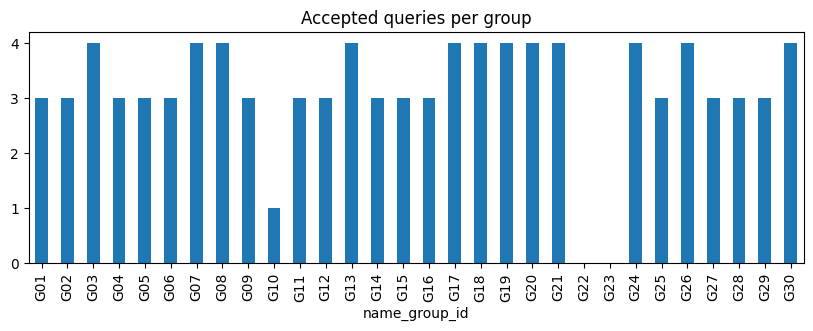

In [21]:
per_group = (acc.groupby(Q_GROUP).size()
              .reindex(groups['name_group_id'], fill_value=0))
print(per_group.describe())
print(per_group[per_group <= 1])
print(acc.groupby('split')[Q_ID].nunique())
per_group.plot(kind='bar', figsize=(10, 3), title='Accepted queries per group')

print(catalogue.groupby('direction_id')['stop_id'].nunique())
names_per = catalogue.groupby('normalized_stop_name')['stop_id'].nunique()
print(names_per.value_counts())

print(cleaning_log['reason'].value_counts())
print('ambiguous rows:', len(ambiguity))

print('names with a slash:',
catalogue['normalized_stop_name'].str.contains('/').sum())
print(catalogue['normalized_stop_name'].str.split().str.len().describe())

*How many names contain a slash, and how long are names in words?*


---


```
print('names with a slash:',
catalogue['normalized_stop_name'].str.contains('/').sum())
print(catalogue['normalized_stop_name'].str.split().str.len().describe())
```
```
names with a slash: 24
count    79.000000
mean      1.822785
std       0.957554
min       1.000000
25%       1.000000
50%       2.000000
75%       2.000000
max       5.000000
Name: normalized_stop_name, dtype: float64
```

**Explanation:** 24 of the 79 catalogue rows contain a slash, so about 30% of stops are affected. Names are short, with a median of 2 words, and at least a quarter are a single word. The rules keep slashes inside tokens, so a name like `bomas/galleria` counts as one word. A query typed with a space instead of the slash shares no token with it, so the token-based score will treat them as different. For one-word names, a single typo removes all token overlap.

---
*How many rows were removed and why?*


---


```
print(cleaning_log['reason'].value_counts())
print('ambiguous rows:', len(ambiguity))
print('total rows received:', len(q), '| usable:', len(acc))
print('share kept:', round(len(acc) / len(q), 3))
```
```
reason
status REJECTED                                13
failed check: stop not in route/direction;      7
Name: count, dtype: int64
ambiguous rows: 6
total rows received: 120 | usable: 94
share kept: 0.783
```

**Explanation:** Of 120 rows, 94 (78%) are usable: 13 were rejected by reviewers, 7 accepted rows failed my check because the expected stop is not served in that route and direction, and 6 were ambiguous (120 = 94 + 13 + 7 + 6). The 7 failures are the surprising part, since a reviewer accepted them. This could be a wrong direction or a wrong stop ID. I cannot tell the cause from counts alone, and I have not changed any row, so these need a look with Kate. Below the 120 target, the real count is 94.

---

*Candidate pools and how many wrong candidates each query faces*

---


```
pairs['is_match'].value_counts()
pairs.groupby('direction_id')['candidate_stop_id'].nunique()
```
```
(paste your output here)
```

**Explanation:** Each query is paired with every stop in its direction, so each has 1 correct candidate and 36 or 41 wrong ones. Matches are only __% of the __ pair rows. A model that always answered 'no match' would score about __% accuracy, so accuracy is misleading here. Precision, recall and per-query success matter more. I report __ queries separately from __ pair rows, since pairs from one query are not independent.

---
*How much shorter or longer are queries than the real name?*
---

```
acc['len_ratio'] = acc['norm_query'].str.len() / acc['group_name'].str.len()
acc.groupby('example_type')['len_ratio'].describe().round(2)
```
```
Output in form of table
```

**Explanation:** EXACT queries should sit at 1.0, TYPO queries close to it, and SHORTENED queries well below. My shortened queries have a median ratio of __, meaning they keep about __% of the name. If this is high, 'shortened' here means a light trim, not a fragment, which makes them easier to match than a very short input would be. This ties to Kate's relative length difference feature.

## Candidate pairs and split checks



In [25]:
rows = []
for r in acc.to_dict('records'):
    mask = (catalogue['route_id'] == r[Q_ROUTE]) & (catalogue['direction_id'] == r[Q_DIR])
    for c in catalogue[mask].to_dict('records'):
        rows.append({
            'pair_id':                  r[Q_ID] + '__' + c['stop_id'],
            'query_id':                 r[Q_ID],
            'name_group_id':            r[Q_GROUP],
            'route_id':                 r[Q_ROUTE],
            'direction_id':             r[Q_DIR],
            'query_text':               r[Q_TEXT],
            'normalized_query':         r['norm_query'],
            'candidate_stop_id':        c['stop_id'],
            'candidate_stop_name':      c['stop_name'],
            'normalized_candidate_name': c['normalized_stop_name'],
            'is_match':                 int(c['stop_id'] == r[Q_STOP]),
        })

pairs = (
    pd.DataFrame(rows)
      .merge(split_df, on='name_group_id', how='left')
      .sort_values('pair_id')
      .reset_index(drop=True)
)

print('queries:', pairs['query_id'].nunique(), 'pairs:', len(pairs))
print(pairs['is_match'].value_counts())

queries: 94 pairs: 3803
is_match
0    3709
1      94
Name: count, dtype: int64


In [32]:
assert pairs['pair_id'].is_unique
assert pairs['split'].notna().all()
assert pairs['is_match'].isin([0, 1]).all()
assert pairs.groupby('query_id')['is_match'].sum().eq(1).all()
assert not pairs.duplicated(['query_id', 'candidate_stop_id']).any()
assert pairs.groupby('name_group_id')['split'].nunique().max() == 1
assert pairs.groupby('normalized_query')['split'].nunique().max() == 1
assert pairs.groupby('query_id')[['route_id', 'direction_id',
'name_group_id', 'split']].nunique().max().max() == 1
assert acc[Q_STATUS].eq('ACCEPTED').all()
assert set(pairs['name_group_id']) <= set(split_df['name_group_id'])
assert groups['normalized_stop_name'].is_unique
print('all checks passed')
print(pairs.groupby('split')['query_id'].nunique())

all checks passed
split
test          21
train         52
validation    21
Name: query_id, dtype: int64


## Export and limitations



In [34]:
import hashlib

SOURCE_ZIP = f'{BASE}/gtfs.zip'
TEMPLATE_PATH = f'{BASE}/DATASET_VERSION_v1.template.txt'

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1 << 20), b''):
            h.update(block)
    return h.hexdigest()

catalogue.to_csv(f'{REVIEWED}/route125_catalogue_v1.csv', index=False)
groups.to_csv(f'{REVIEWED}/selected_name_groups_v1.csv', index=False)
reviewed.to_csv(f'{REVIEWED}/reviewed_queries_v1.csv', index=False)
ambiguity.to_csv(f'{REVIEWED}/ambiguity_challenge_v1.csv', index=False)
pairs.to_csv(f'{REVIEWED}/query_candidate_pairs_v1.csv', index=False)
shutil.copy(f'{SETUP}/split_assignments_v1.csv', f'{REVIEWED}/split_assignments_v1.csv')
cleaning_log.to_csv(f'{BASE}/cleaning_log_v1.csv', index=False)

assert (sha256(f'{SETUP}/split_assignments_v1.csv')
        == sha256(f'{REVIEWED}/split_assignments_v1.csv'))

src_hash = sha256(SOURCE_ZIP) if os.path.exists(SOURCE_ZIP) else 'source zip not found'
split_counts = acc.groupby('split')[Q_ID].nunique().to_dict()

facts = [
    'version: v1',
    'source zip sha256: ' + src_hash,
    f'catalogue rows: {len(catalogue)}',
    f'selected groups: {len(groups)}',
    f'usable queries: {len(acc)}',
    f'usable queries per split: {split_counts}',
    f'ambiguous rows: {len(ambiguity)}',
    f'candidate pairs: {len(pairs)}',
    'checks: all asserts in Cell 10 passed',
]

template_text = open(TEMPLATE_PATH).read() if os.path.exists(TEMPLATE_PATH) else ''


with open(f'{REVIEWED}/DATASET_VERSION_v1.txt', 'w') as f:
    f.write(template_text + '\n\nCOMPUTED FACTS\n' + '\n'.join(facts) + '\n')

SEVEN = [
    'route125_catalogue_v1.csv',
    'selected_name_groups_v1.csv',
    'reviewed_queries_v1.csv',
    'ambiguity_challenge_v1.csv',
    'query_candidate_pairs_v1.csv',
    'split_assignments_v1.csv',
    'DATASET_VERSION_v1.txt'
]

zip_path = f'{BASE}/Bradley_Reviewed_Data_v1.zip'


with zipfile.ZipFile(zip_path, 'w') as z:
    for f in SEVEN:
        z.write(f'{REVIEWED}/{f}', arcname=f)

print(zipfile.ZipFile(zip_path).namelist())

['route125_catalogue_v1.csv', 'selected_name_groups_v1.csv', 'reviewed_queries_v1.csv', 'ambiguity_challenge_v1.csv', 'query_candidate_pairs_v1.csv', 'split_assignments_v1.csv', 'DATASET_VERSION_v1.txt']


# Kate CAT 2 work
Working template only. Write your own code and explanations. No completed analysis or results are supplied.


## Task and inputs
Identify the completed dataset version received from Bradley.


## Input checks
Check the required files, IDs, labels and fixed group split.


In [2]:
import os

print(os.listdir("/content"))

['.config', 'Bradley_Setup_v1.zip', 'sample_data']


In [3]:
import zipfile
import os

zip_path = "/content/Bradley_Setup_v1.zip"
extract_path = "/content/Bradley_Setup"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:")
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

Extracted files:
/content/Bradley_Setup/split_assignments_v1.csv
/content/Bradley_Setup/route125_catalogue_v1.csv
/content/Bradley_Setup/selected_name_groups_v1.csv


In [4]:
import pandas as pd
import os

folder = "/content/Bradley_Setup"

files = [
    "selected_name_groups_v1.csv",
    "split_assignments_v1.csv",
    "route125_catalogue_v1.csv"
]

for filename in files:
    path = os.path.join(folder, filename)
    df = pd.read_csv(path, dtype=str)

    print("\n" + "=" * 50)
    print("FILE:", filename)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))


FILE: selected_name_groups_v1.csv
Shape: (30, 4)
Columns: ['name_group_id', 'normalized_stop_name', 'recorded_stop_name', 'owner']
name_group_id normalized_stop_name recorded_stop_name   owner
          G01                amref              AMREF Bradley
          G02              avocado            Avocado Bradley
          G03      blue sky/t-mall    Blue Sky/T-Mall Bradley

FILE: split_assignments_v1.csv
Shape: (30, 2)
Columns: ['name_group_id', 'split']
name_group_id      split
          G01       test
          G02      train
          G03 validation

FILE: route125_catalogue_v1.csv
Shape: (79, 5)
Columns: ['route_id', 'direction_id', 'stop_id', 'recorded_stop_name', 'normalized_stop_name']
   route_id direction_id stop_id recorded_stop_name normalized_stop_name
50205012511            0 0001RLW           Railways             railways
50205012511            0 0500BAR           Barclays             barclays
50205012511            0 0500BDS       Banda School         banda school


In [5]:
import pandas as pd
import os

folder = "/content/Bradley_Setup"

groups = pd.read_csv(
    os.path.join(folder, "selected_name_groups_v1.csv"),
    dtype=str
)

splits = pd.read_csv(
    os.path.join(folder, "split_assignments_v1.csv"),
    dtype=str
)

# Check that every group has exactly one split assignment
print("Duplicate group assignments:", splits["name_group_id"].duplicated().sum())
print("Groups without a split:", groups[~groups["name_group_id"].isin(splits["name_group_id"])]["name_group_id"].tolist())
print("\nSplit counts:")
print(splits["split"].value_counts().to_string())

# Show Kate's groups and their assigned splits
kate_groups = groups[groups["owner"].str.strip().str.lower() == "kate"]
kate_check = kate_groups.merge(
    splits,
    on="name_group_id",
    how="left",
    validate="one_to_one"
)

print("\nKate's groups and splits:")
print(kate_check[["name_group_id", "normalized_stop_name", "split"]].to_string(index=False))

Duplicate group assignments: 0
Groups without a split: []

Split counts:
split
train         18
test           6
validation     6

Kate's groups and splits:
name_group_id               normalized_stop_name      split
          G16                             nafrom      train
          G17         nairobi national park gate      train
          G18                             naston validation
          G19                 nibs/ongata rongai validation
          G20                              nyotu      train
          G21 ongata rongai police station/nyotu       test
          G22                         park place      train
          G23                           railways      train
          G24                              shell       test
          G25      shell haile selassie junction validation
          G26                       shell/t-mall      train
          G27                              swara      train
          G28                             tuskys      train
   

In [6]:
import pandas as pd
import os

folder = "/content/Bradley_Setup"

groups = pd.read_csv(
    os.path.join(folder, "selected_name_groups_v1.csv"),
    dtype=str
)

catalogue = pd.read_csv(
    os.path.join(folder, "route125_catalogue_v1.csv"),
    dtype=str
)

# Keep only Kate's selected groups
kate_groups = groups[
    groups["owner"].str.strip().str.lower() == "kate"
]

print("Catalogue columns:")
print(catalogue.columns.tolist())

print("\nRoute IDs:", catalogue["route_id"].unique().tolist())
print("Directions:", sorted(catalogue["direction_id"].unique().tolist()))
print("Unique stop IDs:", catalogue["stop_id"].nunique())

print("\nChecking Kate's selected names against the catalogue:")
for _, group in kate_groups.iterrows():
    matches = catalogue[
        catalogue["normalized_stop_name"].str.strip().str.lower()
        == group["normalized_stop_name"].strip().lower()
    ]

    print(
        group["name_group_id"],
        "|", group["normalized_stop_name"],
        "| catalogue matches:", len(matches),
        "| directions:", matches["direction_id"].tolist()
    )

Catalogue columns:
['route_id', 'direction_id', 'stop_id', 'recorded_stop_name', 'normalized_stop_name']

Route IDs: ['50205012511']
Directions: ['0', '1']
Unique stop IDs: 78

Checking Kate's selected names against the catalogue:
G16 | nafrom | catalogue matches: 1 | directions: ['1']
G17 | nairobi national park gate | catalogue matches: 1 | directions: ['1']
G18 | naston | catalogue matches: 1 | directions: ['0']
G19 | nibs/ongata rongai | catalogue matches: 1 | directions: ['1']
G20 | nyotu | catalogue matches: 1 | directions: ['0']
G21 | ongata rongai police station/nyotu | catalogue matches: 1 | directions: ['1']
G22 | park place | catalogue matches: 2 | directions: ['0', '1']
G23 | railways | catalogue matches: 2 | directions: ['0', '1']
G24 | shell | catalogue matches: 1 | directions: ['0']
G25 | shell haile selassie junction | catalogue matches: 1 | directions: ['1']
G26 | shell/t-mall | catalogue matches: 1 | directions: ['1']
G27 | swara | catalogue matches: 1 | directions: [

## Features
Write and explain the four agreed features.




*   exact_match: It checks whether the passengers input or query and the catalogue names are exactly the same after normalisation. 1 = Names match exactly while 0 = names are different.
*   char_similarity: measures how similar two strings are by each character. Uses Levenshtein edit distance.1 means identical; a higher score means a higher similarity.
*   token_jaccard: measures how many words two names have in common
*   relative_length_difference: calculates the number of characters in two names and gets the difference, then it divides it with the length of the longer number.



In [12]:
import unicodedata
import pandas as pd
from rapidfuzz.distance import Levenshtein


# Normalize the stop names

def normalize_name(name):
    # Handle missing values so that NaN does not become the text "nan"
    if pd.isna(name):
        return ""

    # Standardize equivalent Unicode representations
    name = unicodedata.normalize("NFKC", str(name))

    # Convert all letters to lowercase
    name = name.lower()

    # Remove spaces at the beginning and end
    name = name.strip()

    # Replace repeated spaces with one space
    name = " ".join(name.split())

    return name


# ============================================
# 3. CALCULATE FEATURES FOR ONE PAIR
# ============================================

def calculate_features(query, candidate):
    # Normalize both names before comparing them
    query = normalize_name(query)
    candidate = normalize_name(candidate)

    # Do not calculate features for blank names
    if not query or not candidate:
        raise ValueError(
            "Query and candidate names must not be blank."
        )

    # FEATURE 1: Exact Match
    # 1 if the normalized names are identical; otherwise 0
    exact_match = int(query == candidate)

    # FEATURE 2: Character Similarity
    # Compares characters using normalized Levenshtein similarity.
    # The result is between 0 and 1.
    char_similarity = Levenshtein.normalized_similarity(
        query, candidate
    )

    # FEATURE 3: Token Jaccard Similarity
    # Split names into words and remove repeated words using sets
    query_words = set(query.split())
    candidate_words = set(candidate.split())

    # Count words shared by both names
    common_words = query_words.intersection(candidate_words)

    # Count all distinct words appearing in either name
    all_words = query_words.union(candidate_words)

    # Calculate the proportion of shared words
    token_jaccard = len(common_words) / len(all_words)

    # FEATURE 4: Relative Length Difference
    # Compare the character lengths of the two normalized names
    longer_length = max(len(query), len(candidate))

    relative_length_difference = (
        abs(len(query) - len(candidate)) / longer_length
    )

    # Return the four features in the required order
    return {
        "exact_match": exact_match,
        "char_similarity": char_similarity,
        "token_jaccard": token_jaccard,
        "relative_length_difference": relative_length_difference
    }


# ============================================
# 4. BUILD FEATURES FOR A WHOLE DATAFRAME
# ============================================

def build_features(pairs_dataframe):
    # These are assumed column names.
    # Confirm them against Bradley's reviewed dataset.
    required_columns = ["query", "candidate_name"]

    # Check that the required columns exist
    for column in required_columns:
        if column not in pairs_dataframe.columns:
            raise ValueError(
                f"Missing required column: {column}. "
                f"Available columns: {list(pairs_dataframe.columns)}"
            )

    # Store the features calculated for each row
    feature_rows = []

    # Process each query-candidate pair without changing row order
    for _, row in pairs_dataframe.iterrows():

        # Calculate all four features using our existing function
        features = calculate_features(
            row["query"],
            row["candidate_name"]
        )

        # Add the results for this pair
        feature_rows.append(features)

    # Define the exact feature column order required by the project
    feature_columns = [
        "exact_match",
        "char_similarity",
        "token_jaccard",
        "relative_length_difference"
    ]

    # Return only the four features, preserving the original index
    features_dataframe = pd.DataFrame(
        feature_rows,
        columns=feature_columns,
        index=pairs_dataframe.index
    )

    return features_dataframe


# ============================================
# 5. TEST THE FUNCTIONS
# ============================================

# Test normalization
print("Normalized name:")
print(normalize_name("  Nafrom  "))

# Test one identical pair
print("\nTest 1: Identical names")
print(calculate_features("Nafrom", "Nafrom"))

# Test one pair with a spelling difference
print("\nTest 2: Names with a spelling difference")
print(calculate_features("nafom", "nafrom"))

# Test build_features using a small example
# This is only a function test, not project training data.
test_pairs = pd.DataFrame({
    "query": ["Nafrom", "nafom"],
    "candidate_name": ["Nafrom", "nafrom"]
})

test_features = build_features(test_pairs)

print("\nFeatures for the test pairs:")
print(test_features)

# Check the required feature columns
print("\nFeature columns:")
print(list(test_features.columns))

# Check that the number of output rows matches the input
assert len(test_features) == len(test_pairs)

# Check the exact required column order
assert list(test_features.columns) == [
    "exact_match",
    "char_similarity",
    "token_jaccard",
    "relative_length_difference"
]

print("\nAll feature function tests passed!")


Normalized name:
nafrom

Test 1: Identical names
{'exact_match': 1, 'char_similarity': 1.0, 'token_jaccard': 1.0, 'relative_length_difference': 0.0}

Test 2: Names with a spelling difference
{'exact_match': 0, 'char_similarity': 0.8333333333333334, 'token_jaccard': 0.0, 'relative_length_difference': 0.16666666666666666}

Features for the test pairs:
   exact_match  char_similarity  token_jaccard  relative_length_difference
0            1         1.000000            1.0                    0.000000
1            0         0.833333            0.0                    0.166667

Feature columns:
['exact_match', 'char_similarity', 'token_jaccard', 'relative_length_difference']

All feature function tests passed!


In [9]:
# Test the features using two identical names
result = calculate_features("Nafrom", "Nafrom")

print(result)

{'exact_match': 1, 'char_similarity': 1.0, 'token_jaccard': 1.0, 'relative_length_difference': 0.0}


In [10]:
# Compare the correct stop name with a misspelled query
result = calculate_features("nafom", "nafrom")

print(result)

{'exact_match': 0, 'char_similarity': 0.8333333333333334, 'token_jaccard': 0.0, 'relative_length_difference': 0.16666666666666666}


## Training-only cross validation
Use three group-aware folds with fresh pipelines.


## Base model
Fit the agreed final pipeline on train only.


## Validation results
Record real validation predictions, metrics and errors.


## Handoff and limitations
Save the six completed model outputs. Do not evaluate test.


In [7]:
%pip install rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 46.4 MB/s  0:00:00
